# 06 – Thermal model and thermal index of the candidates

A hanging glacier frozen to its bed (cold base) is held by the bed; if the base warms to the melting point,
it can slide and break off. The thermal question is therefore: **is the base of each candidate below the
melting point, and how fast would a surface warming reach it?**

- **Data:** boreholes of Beer et al. (2026) in glenglat: 6 Swiss sites (2,760–3,820 m), measured with the same
  method in 2024–2026, including Alphubel and Chessjengletscher in the study area (`src/boreholes.py`).
- **Model:** 1D heat conduction in the ice column (`src/heat1d.py`), from a depth of ~15 m (below the seasonal
  cycle) to the bed, with the geothermal flux at the bed and the pressure melting point as an upper bound.
- **Thermal index:** probability that the base is cold, given the uncertainty on the near-surface temperature,
  and the response time of the base to a surface warming.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from scipy import ndimage
from scipy.stats import norm

import boreholes as bh
import heat1d as h
from config import CRS, DEM_RES, PROCESSED, RAW

FIG = ROOT / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200)
SITE_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

bore = bh.boreholes()
prof = bh.annual_profiles()
t_ns = bh.near_surface_temperature(prof)
table = bore.loc[prof["borehole_id"].unique(), ["glacier_name", "label", "elevation", "depth", "to_bed"]]
table["T_10_20m"] = t_ns
table = table.sort_values(["glacier_name", "label"])
sites = sorted(table["glacier_name"].unique())
colour = dict(zip(sites, SITE_COLOURS))
print(f"{len(table)} boreholes with ≥ 300 days of equilibrium data, {len(sites)} sites")
table.round(2)

21 boreholes with ≥ 300 days of equilibrium data, 6 sites


,glacier_name,label,elevation,depth,to_bed,T_10_20m
id,,,,,,
877,Alphubel South,AH1G,3802.0,50.60,True,-0.99
885,Alphubel South,AH1TT,3775.0,15.00,False,-2.90
878,Alphubel South,AH2G,3759.0,20.30,True,-2.76
886,Alphubel South,AH2TT,3789.0,14.00,False,-2.20
879,Alphubel South,AH3G,3820.0,58.30,True,-0.01
887,Alphubel South,AH3TT,3781.0,17.00,False,-1.81
883,Chessjengletscher,CJ1G,3031.0,38.30,True,-0.82
888,Chessjengletscher,CJ1TT,2983.0,11.80,False,-0.98
884,Chessjengletscher,CJ2G,3005.0,17.00,True,-0.68


## 1. Measured profiles (mean of the last 12 months)

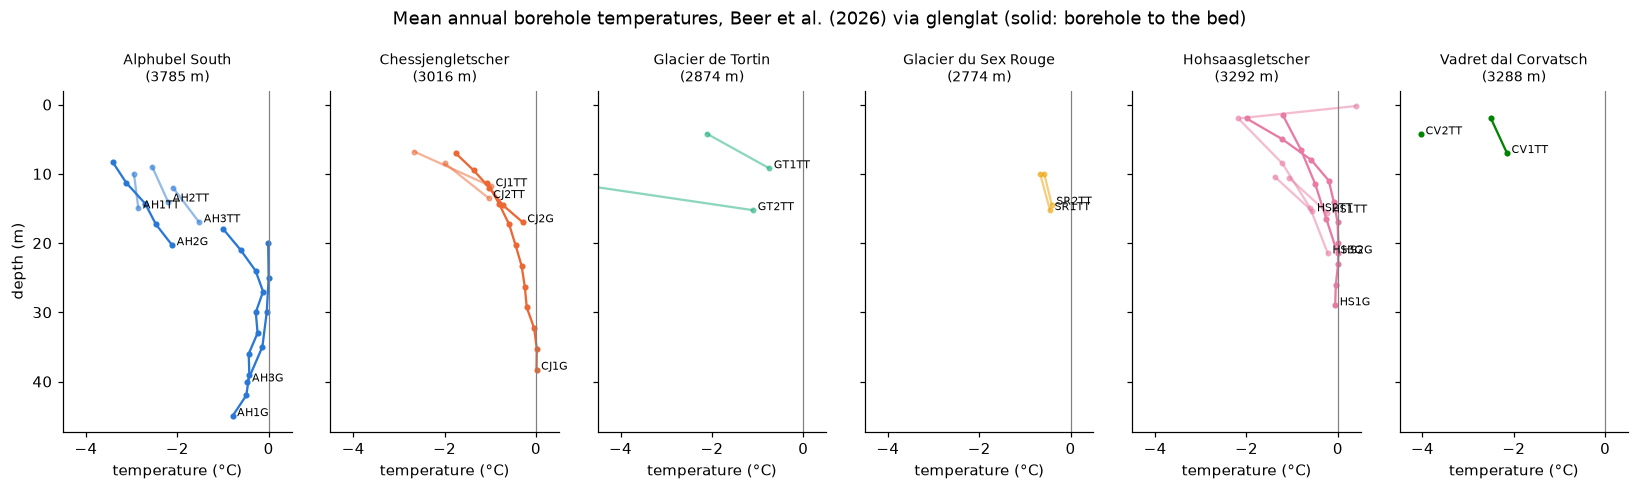

In [2]:
fig, axes = plt.subplots(1, len(sites), figsize=(15, 4.5), sharey=True)
for ax, site in zip(axes, sites):
    for bid in table.index[table["glacier_name"] == site]:
        p = prof[prof["borehole_id"] == bid]
        ax.plot(p["temperature"], p["depth"], "o-", ms=3, lw=1.5, color=colour[site],
                alpha=1 if bore.loc[bid, "to_bed"] else 0.5)
        ax.annotate(bore.loc[bid, "label"], (p["temperature"].iloc[-1], p["depth"].iloc[-1]), fontsize=7,
                    xytext=(3, 0), textcoords="offset points")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{site}\n({table.loc[table['glacier_name'] == site, 'elevation'].median():.0f} m)", fontsize=9)
    ax.set_xlim(-4.5, 0.5)
    ax.set_xlabel("temperature (°C)")
axes[0].set_ylabel("depth (m)")
axes[0].invert_yaxis()
fig.suptitle("Mean annual borehole temperatures, Beer et al. (2026) via glenglat (solid: borehole to the bed)")
fig.tight_layout()
fig.savefig(FIG / "06_borehole_profiles.png", dpi=150)

## 2. Near-surface temperature and elevation

The temperature at 10–20 m depth is the upper boundary of the model. Can it be predicted from elevation?
Leave-one-site-out: the relation is fitted on 5 sites and tested on the 6th, compared with simply using the
mean of the 5 other sites. The model with the lower error is used for the candidates (rule set before the test).

     linear in elevation: leave-one-site-out RMSE 1.55 °C
 mean of the other sites: leave-one-site-out RMSE 1.18 °C
model used for the candidates: constant, -1.50 °C (mean of the site means), uncertainty ± 1.18 °C
fit on all sites: T = 0.89 + -0.63 °C/km × elevation; correlation r = -0.23


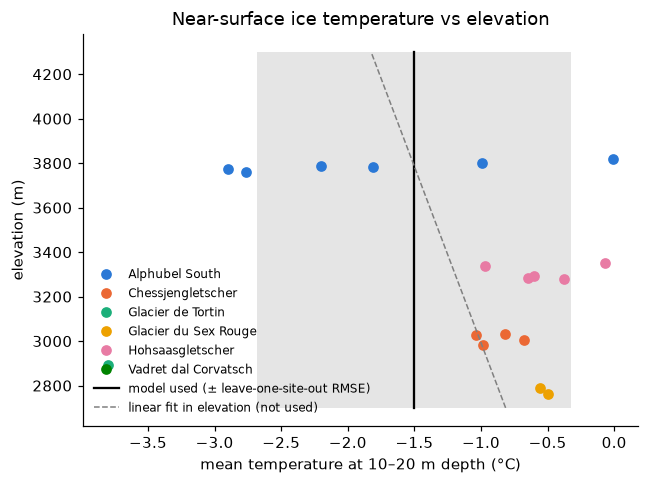

In [3]:
d = table.dropna(subset=["T_10_20m"])
errors = {"linear in elevation": [], "mean of the other sites": []}
for site in sites:
    train, test = d[d["glacier_name"] != site], d[d["glacier_name"] == site]
    if test.empty:
        continue
    fit = np.polyfit(train["elevation"], train["T_10_20m"], 1)
    errors["linear in elevation"] += list(test["T_10_20m"] - np.polyval(fit, test["elevation"]))
    errors["mean of the other sites"] += list(test["T_10_20m"] - train["T_10_20m"].mean())
for k, e in errors.items():
    print(f"{k:>24}: leave-one-site-out RMSE {np.sqrt(np.mean(np.square(e))):.2f} °C")

rmse = {k: np.sqrt(np.mean(np.square(e))) for k, e in errors.items()}
FIT = np.polyfit(d["elevation"], d["T_10_20m"], 1)
USE_ELEVATION = rmse["linear in elevation"] < rmse["mean of the other sites"]
T_MEAN = d.groupby("glacier_name")["T_10_20m"].mean().mean()          # mean of the site means
SIGMA = min(rmse.values())                                            # uncertainty used for the candidates
print(f"model used for the candidates: {'linear in elevation' if USE_ELEVATION else f'constant, {T_MEAN:.2f} °C (mean of the site means)'}, "
      f"uncertainty ± {SIGMA:.2f} °C")
print(f"fit on all sites: T = {FIT[1]:.2f} + {FIT[0] * 1000:.2f} °C/km × elevation; "
      f"correlation r = {np.corrcoef(d['elevation'], d['T_10_20m'])[0, 1]:.2f}")

fig, ax = plt.subplots(figsize=(6, 4.5))
for site in sites:
    s = d[d["glacier_name"] == site]
    ax.plot(s["T_10_20m"], s["elevation"], "o", color=colour[site], label=site)
zz = np.linspace(2700, 4300, 50)
used = np.polyval(FIT, zz) if USE_ELEVATION else np.full_like(zz, T_MEAN)
ax.plot(used, zz, color="black", lw=1.5, label="model used (± leave-one-site-out RMSE)")
ax.fill_betweenx(zz, used - SIGMA, used + SIGMA, color="grey", alpha=0.2, lw=0)
if not USE_ELEVATION:
    ax.plot(np.polyval(FIT, zz), zz, "--", color="grey", lw=1, label="linear fit in elevation (not used)")
ax.set(xlabel="mean temperature at 10–20 m depth (°C)", ylabel="elevation (m)",
       title="Near-surface ice temperature vs elevation")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "06_near_surface_temperature.png", dpi=150)

## 3. Does conduction alone explain the profiles?

For each borehole that reaches the bed, the model is started from the measured mean temperature at the
shallowest sensor below 8 m, with the bed at the drilled depth. Two versions:

- **steady state**: the profile the column would reach with today's upper temperature;
- **warming**: the column was in steady state 40 years ago with an upper temperature 1.6 °C colder, then warmed
  at 0.4 °C per decade (an assumed order of magnitude for the Alps, to be checked [verify]).

The error is the root mean square difference with the measured sensors.

,borehole,site,bed_depth,deepest_measured,steady_at_deepest,rmse_steady,rmse_warming
0,AH1G,Alphubel South,50.6,-0.79,-0.09,0.40,0.54
1,AH2G,Alphubel South,20.3,-2.11,-3.01,0.62,0.68
2,AH3G,Alphubel South,58.3,-0.47,-0.03,0.22,0.18
3,CJ1G,Chessjengletscher,38.3,0.01,-0.17,0.29,0.59
4,CJ2G,Chessjengletscher,17.0,-0.29,-1.11,0.57,0.59
5,HS1G,Hohsaasgletscher,29.0,-0.06,-0.03,0.20,0.33
6,HS2G,Hohsaasgletscher,21.5,-0.01,-0.16,0.12,0.17


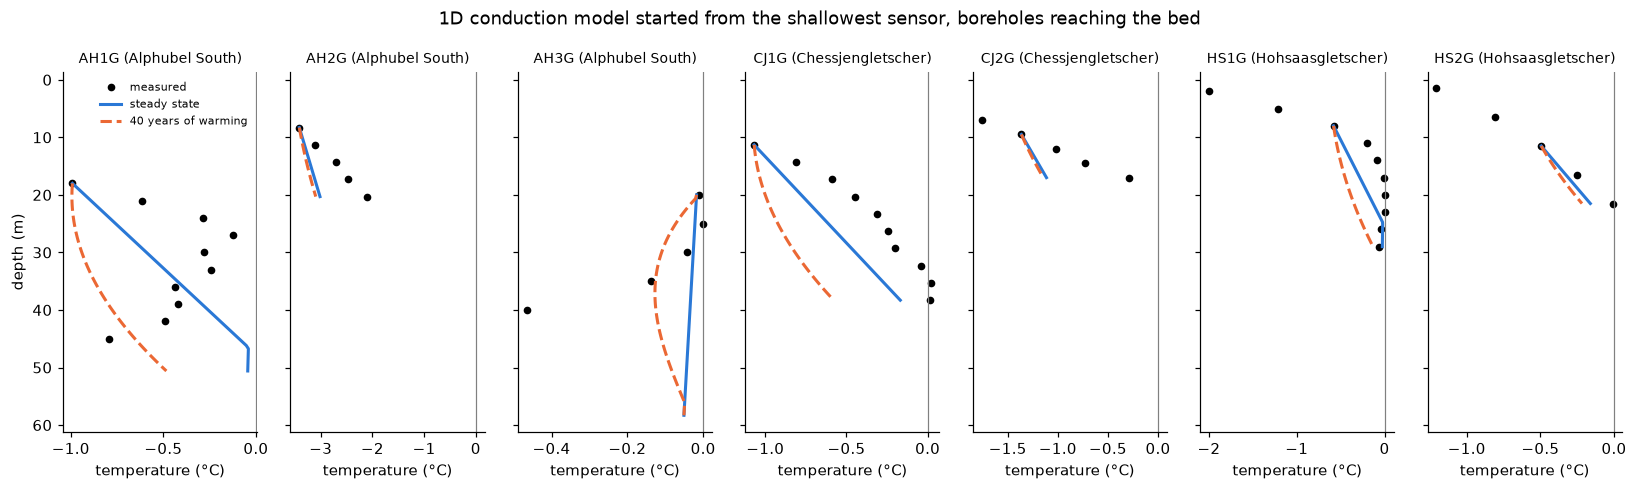

In [4]:
WARMING = 0.04   # °C per year
YEARS = 40


def model_profiles(bid):
    p = prof[prof["borehole_id"] == bid].sort_values("depth")
    top = p[p["depth"] >= 8].iloc[0]
    H = float(bore.loc[bid, "depth"])
    z = np.linspace(top["depth"], H, 60)
    steady = h.steady_profile(top["temperature"], top["depth"], z)
    t0 = top["temperature"] - WARMING * YEARS
    start = h.steady_profile(t0, top["depth"], z)
    _, run = h.transient(start, z, lambda t: t0 + WARMING * t, YEARS)
    return p, top, z, steady, run[-1]


rows = []
bed_boreholes = table.index[table["to_bed"] & (table["depth"] > 15)]
fig, axes = plt.subplots(1, len(bed_boreholes), figsize=(15, 4.5), sharey=True)
for ax, bid in zip(axes, bed_boreholes):
    p, top, z, steady, warm = model_profiles(bid)
    below = p[p["depth"] > top["depth"]]
    err = lambda m: np.sqrt(np.mean((np.interp(below["depth"], z, m) - below["temperature"]) ** 2))
    rows.append({"borehole": bore.loc[bid, "label"], "site": bore.loc[bid, "glacier_name"],
                 "bed_depth": bore.loc[bid, "depth"], "deepest_measured": p["temperature"].iloc[-1],
                 "steady_at_deepest": np.interp(p["depth"].iloc[-1], z, steady),
                 "rmse_steady": err(steady), "rmse_warming": err(warm)})
    ax.plot(p["temperature"], p["depth"], "o", color="black", ms=4, label="measured")
    ax.plot(steady, z, color="#2a78d6", lw=2, label="steady state")
    ax.plot(warm, z, "--", color="#eb6834", lw=2, label="40 years of warming")
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"{bore.loc[bid, 'label']} ({bore.loc[bid, 'glacier_name']})", fontsize=9)
    ax.set_xlabel("temperature (°C)")
axes[0].set_ylabel("depth (m)")
axes[0].invert_yaxis()
axes[0].legend(fontsize=7, frameon=False)
fig.suptitle("1D conduction model started from the shallowest sensor, boreholes reaching the bed")
fig.tight_layout()
fig.savefig(FIG / "06_model_vs_boreholes.png", dpi=150)
validation = pd.DataFrame(rows).round(2)
validation

## 4. Ice thickness of the candidates

No thickness is measured for the candidates. For a glacier at the yield stress, the thickness follows from
the surface slope α: H = τ / (ρ g sin α), with τ = 100 kPa (perfect plasticity, Cuffey & Paterson 2010 [verify]).
Checked against the depth to bed of the boreholes in the study area (slope = mean surface slope within 50 m).

In [5]:
TAU = 100e3
plastic = lambda slope_deg: TAU / (h.RHO * 9.81 * np.sin(np.radians(slope_deg)))

with rasterio.open(PROCESSED / f"slope_{DEM_RES}m.tif") as src:
    slope_grid = src.read(1)
    transform = src.transform
smooth_slope = ndimage.uniform_filter(np.nan_to_num(slope_grid), 11)   # mean over ~110 m (≈ 50 m radius)
pts = bore[bore["to_bed"]].copy()
pts = gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts["longitude"], pts["latitude"]), crs=4326).to_crs(CRS)
rows = []
for bid, p in pts.iterrows():
    col, row = ~transform * (p.geometry.x, p.geometry.y)
    if 0 <= int(row) < slope_grid.shape[0] and 0 <= int(col) < slope_grid.shape[1] and not np.isnan(slope_grid[int(row), int(col)]):
        s = smooth_slope[int(row), int(col)]
        rows.append({"borehole": p["label"], "site": p["glacier_name"], "slope": s,
                     "depth_to_bed": p["depth"], "plastic_thickness": plastic(s)})
thick = pd.DataFrame(rows).round(1)
ratio = thick["depth_to_bed"] / thick["plastic_thickness"]
print(f"measured / plastic thickness: {ratio.min():.1f}–{ratio.max():.1f} (median {ratio.median():.1f})")
thick

measured / plastic thickness: 0.6–2.6 (median 1.2)


,borehole,site,slope,depth_to_bed,plastic_thickness
0,AH1G,Alphubel South,30.000000,50.6,22.299999
1,AH2G,Alphubel South,30.400000,20.3,22.000000
2,AH3G,Alphubel South,29.900000,58.3,22.299999
3,CJ1G,Chessjengletscher,20.200001,38.3,32.200001
4,CJ2G,Chessjengletscher,21.299999,17.0,30.500000


## 5. Thermal index of the candidates

For each candidate (notebook 05):

1. near-surface temperature from the model chosen in section 2 (elevation does not help: a constant, the mean
   of the site means), uncertainty ± σ (leave-one-site-out RMSE);
2. thickness from its mean slope (section 4), kept between 10 and 100 m;
3. steady-state basal temperature (section 3);
4. **P(cold base)** = probability that the basal temperature is below the melting point, if the error on the
   near-surface temperature is normal with standard deviation σ;
5. **response time** H² / κ: years for a surface warming to reach the bed.

In [6]:
cand = gpd.read_file(PROCESSED / "candidates.gpkg", layer="candidates")
with rasterio.open(PROCESSED / f"dem_{DEM_RES}m.tif") as src:
    dem = src.read(1)
grid = rasterize(zip(cand.geometry, cand["candidate_id"]), out_shape=dem.shape, transform=transform, fill=0)
cand["z_mean"] = ndimage.mean(dem, grid, cand["candidate_id"])

Z_TOP = 15
cand["T_near_surface"] = np.polyval(FIT, cand["z_mean"]) if USE_ELEVATION else T_MEAN
cand["thickness"] = plastic(cand["slope_mean"]).clip(10, 100)
cand["T_base"] = h.basal_temperature(cand["T_near_surface"], Z_TOP, np.maximum(cand["thickness"], Z_TOP))
margin = h.melting_point(cand["thickness"]) - (cand["T_near_surface"] + h.G / h.K * (np.maximum(cand["thickness"], Z_TOP) - Z_TOP))
cand["P_cold_base"] = norm.cdf(margin / SIGMA)
cand["response_years"] = h.response_time(cand["thickness"])

cols = ["rank", "candidate_id", "glacier", "z_mean", "slope_mean", "thickness", "T_near_surface", "T_base",
        "P_cold_base", "response_years", "geometric_index"]
ranking = cand.sort_values("rank")[cols].round({"z_mean": 0, "slope_mean": 1, "thickness": 0, "T_near_surface": 2,
                                                "T_base": 2, "P_cold_base": 2, "response_years": 0,
                                                "geometric_index": 3})
ranking.to_csv(ROOT / "report" / "candidates_ranking.csv", index=False)
cand.drop(columns="geometry").to_csv(PROCESSED / "candidates_thermal.csv", index=False)
print(f"P(cold base): median {cand['P_cold_base'].median():.2f}, "
      f"{(cand['P_cold_base'] > 0.8).sum()} candidates above 0.8, {(cand['P_cold_base'] < 0.5).sum()} below 0.5")
print(f"thickness: median {cand['thickness'].median():.0f} m; response time: median {cand['response_years'].median():.0f} years "
      f"({cand['response_years'].min():.0f}–{cand['response_years'].max():.0f})")
ranking.head(20)

P(cold base): median 0.87, 147 candidates above 0.8, 0 below 0.5
thickness: median 20 m; response time: median 11 years (6–80)


,rank,candidate_id,glacier,z_mean,slope_mean,thickness,T_near_surface,T_base,P_cold_base,response_years,geometric_index
146,1,147,Zmuttgletscher,3716.0,43.7,16.0,-1.5,-1.47,0.89,7.0,0.898
97,2,98,Glacier de Zinal,3912.0,51.0,14.0,-1.5,-1.50,0.90,6.0,0.868
57,3,58,Glacier de Moming,3767.0,41.5,17.0,-1.5,-1.44,0.89,8.0,0.859
90,4,91,Glacier de Zinal,3770.0,40.4,17.0,-1.5,-1.43,0.89,8.0,0.845
93,5,94,Glacier de Zinal,3401.0,37.4,18.0,-1.5,-1.39,0.88,10.0,0.828
48,6,49,Kingletscher,4167.0,41.6,17.0,-1.5,-1.45,0.89,8.0,0.821
35,7,36,Hohbalmgletscher,4083.0,49.3,15.0,-1.5,-1.50,0.90,6.0,0.801
54,7,55,Glacier de Moming,3448.0,40.5,17.0,-1.5,-1.43,0.89,8.0,0.801
36,9,37,Bisgletscher,4169.0,45.5,16.0,-1.5,-1.48,0.89,7.0,0.795
45,10,46,Festigletscher,4252.0,45.3,16.0,-1.5,-1.48,0.89,7.0,0.767


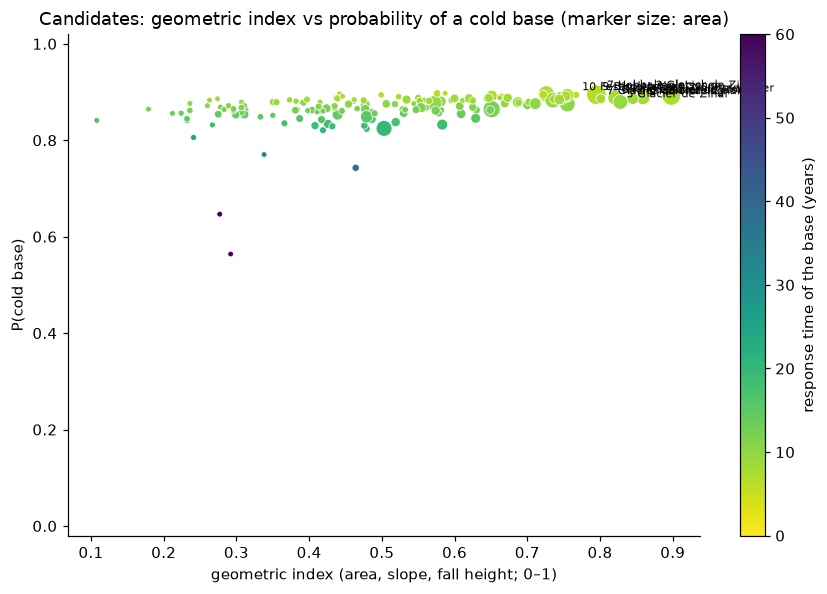

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sc = ax.scatter(cand["geometric_index"], cand["P_cold_base"], s=10 + cand["area_ha"] * 4,
                c=cand["response_years"], cmap="viridis_r", vmin=0, vmax=60, edgecolor="white", linewidth=0.5)
for _, c in cand.nsmallest(10, "rank").iterrows():
    ax.annotate(f"{c['rank']} {c['glacier']}", (c["geometric_index"], c["P_cold_base"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
fig.colorbar(sc, ax=ax, label="response time of the base (years)")
ax.set(xlabel="geometric index (area, slope, fall height; 0–1)", ylabel="P(cold base)",
       title="Candidates: geometric index vs probability of a cold base (marker size: area)")
ax.set_ylim(-0.02, 1.02)
fig.tight_layout()
fig.savefig(FIG / "06_geometric_vs_thermal.png", dpi=150)

## 6. How fast does a warming reach the bed?

Illustration: columns of 20, 40 and 60 m, in steady state with −2 °C at 15 m depth, then warmed at 0.4 °C per decade.

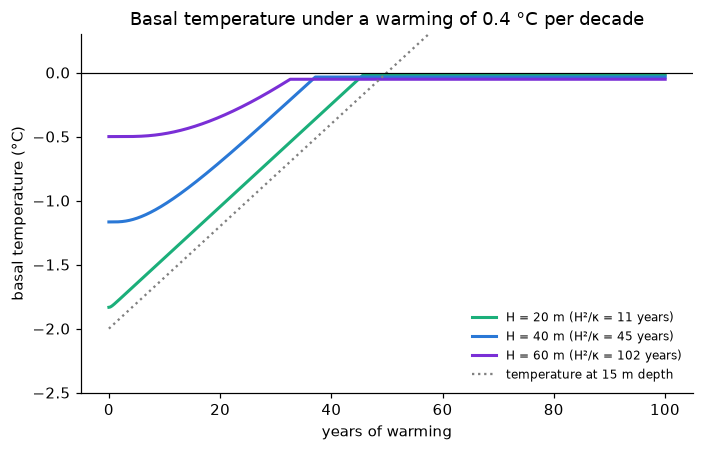

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for H, col in zip([20, 40, 60], ["#1baf7a", "#2a78d6", "#7a2fd6"]):
    z = np.linspace(Z_TOP, H, 50)
    t, run = h.transient(h.steady_profile(-2.0, Z_TOP, z), z, lambda t: -2.0 + WARMING * t, 100, dt_days=30)
    ax.plot(t, run[:, -1], color=col, lw=2, label=f"H = {H} m (H²/κ = {h.response_time(H):.0f} years)")
ax.plot(t, -2.0 + WARMING * t, ":", color="grey", label="temperature at 15 m depth")
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="years of warming", ylabel="basal temperature (°C)", ylim=(-2.5, 0.3),
       title="Basal temperature under a warming of 0.4 °C per decade")
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG / "06_warming_response.png", dpi=150)